In [ ]:
!pip install -q transformers imbalanced-learn langdetect openpyxl sentencepiece scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 43.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import os, re, json, time, random, copy, glob
import numpy as np, pandas as pd, torch
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, cohen_kappa_score)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from scipy.stats import binomtest
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from langdetect import detect, DetectorFactory, LangDetectException
import warnings; warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

repo_url =

!git clone {repo_url}

Device: cuda
Cloning into 'TugasAkhir'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 18 (delta 4), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 5.33 MiB | 19.64 MiB/s, done.
Resolving deltas: 100% (4/4), done.


## Konfigurasi
Clone repo seperti biasa (pakai token baru — token lama sebaiknya sudah di-revoke), atau upload dua file Excel ke `/content/`.
Lalu sesuaikan path di bawah.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_RAW     = '/content/TugasAkhir/DATA.xlsx'
DATA_LABELED = '/content/TugasAkhir/DATA SENTIMEN.xlsx'
OUT_DIR      = '/content/drive/MyDrive/wukong_revisi'

MODELS = {'BERT': 'bert-base-uncased', 'RoBERTa': 'roberta-base'}


SCENARIOS    = ['original', 'oversampling', 'downsampling', 'class_weighted']
SEEDS        = [42, 43, 44, 45, 46]
RUN_ABLATION = True

MAX_LEN, BATCH, LR, WD, EPS = 128, 32, 2e-5, 0.01, 1e-8
MAX_EPOCHS, PATIENCE, WARMUP = 10, 2, 0.1
LABEL_MAP = {'Negatif': 0, 'Positif': 1, 'Netral': 2}
CLASSES = ['Negative', 'Positive', 'Neutral']

for sub in ['', 'preds', 'hist']:
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
STATS = {}
def save_stats():
    json.dump(STATS, open(f'{OUT_DIR}/data_stats.json', 'w'), indent=2, default=str)

Mounted at /content/drive


## Preprocessing (sama persis dengan notebook lama) + versi minimal untuk ablation

In [ ]:
def remove_url(t):  return re.sub(r'http\S+|www\.\S+', '', t)
def remove_html(t): return re.sub(r'<[^>]+>', '', t)
EMOJI = re.compile("[" "\U0001F600-\U0001F64F" "\U0001F300-\U0001F5FF" "\U0001F680-\U0001F6FF"
                   "\U0001F1E0-\U0001F1FF" "\U00002700-\U000027BF" "\U000024C2-\U0001F251" "]+", flags=re.UNICODE)
def preprocess_text(text):
    if not isinstance(text, str): return ''
    t = remove_url(text); t = remove_html(t); t = EMOJI.sub('', t)
    t = t.encode('ascii', errors='ignore').decode('ascii')
    t = re.sub(r'[^a-zA-Z\s]', '', t).strip().lower()
    t = re.sub(r'\s+', ' ', t).strip()
    t = re.compile(r'(.)\1{3,}', re.IGNORECASE).sub(lambda m: m.group(1) * 3, t)
    return t

def minimal_preprocess(text):
    """Ablation: hanya hapus URL/HTML dan rapikan spasi. Emoji, angka, tanda baca, huruf besar dipertahankan."""
    if not isinstance(text, str): return ''
    return re.sub(r'\s+', ' ', remove_html(remove_url(text))).strip()

DetectorFactory.seed = 0
def detect_lang(t):
    try: return detect(str(t))
    except LangDetectException: return 'unknown'

## 1. Jumlah data per tahap, deteksi bahasa, dan pencocokan label dengan recommendation flag

In [ ]:
raw = pd.read_excel(DATA_RAW)
STATS['n_raw'] = len(raw)
raw = raw.dropna(subset=['reviewText', 'reviewResult'])
raw = raw[raw['reviewText'].astype(str).str.strip() != '']
STATS['n_after_empty_removed'] = len(raw)
raw['clean_text'] = raw['reviewText'].apply(preprocess_text)
raw = raw[raw['clean_text'].str.strip() != ''].reset_index(drop=True)
STATS['n_after_preprocessing'] = len(raw)

print('Deteksi bahasa (teks bersih & teks mentah) ... beberapa menit')
raw['lang_clean'] = raw['clean_text'].apply(detect_lang)
raw['lang_raw']   = raw['reviewText'].astype(str).apply(detect_lang)
STATS['lang_clean_counts'] = raw['lang_clean'].value_counts().head(15).to_dict()
STATS['lang_raw_counts']   = raw['lang_raw'].value_counts().head(15).to_dict()
STATS['n_en_clean'] = int((raw['lang_clean'] == 'en').sum())
STATS['n_en_raw']   = int((raw['lang_raw'] == 'en').sum())
STATS['en_raw_but_not_en_clean'] = int(((raw['lang_raw'] == 'en') & (raw['lang_clean'] != 'en')).sum())
STATS['en_clean_but_not_en_raw'] = int(((raw['lang_clean'] == 'en') & (raw['lang_raw'] != 'en')).sum())

lab = pd.read_excel(DATA_LABELED)
STATS['n_labeled_file'] = len(lab)
lab['label'] = lab['Sentimen'].map(LABEL_MAP)
STATS['n_missing_label'] = int(lab['label'].isna().sum())
lab = lab.dropna(subset=['label']).reset_index(drop=True)
lab['label'] = lab['label'].astype(int)
lab['Text'] = lab['Text'].astype(str)
STATS['n_labeled'] = len(lab)

first = raw.drop_duplicates('clean_text').set_index('clean_text')
lab['reviewText']   = lab['Text'].map(first['reviewText'])
lab['reviewResult'] = lab['Text'].map(first['reviewResult'])
lab['lang_raw']     = lab['Text'].map(first['lang_raw'])
STATS['n_labeled_matched_to_raw'] = int(lab['reviewText'].notna().sum())
STATS['labeled_lang_raw_counts']  = lab['lang_raw'].value_counts().head(10).to_dict()

m = lab.dropna(subset=['reviewResult'])
ct = pd.crosstab(m['Sentimen'], m['reviewResult'])
print(ct)
STATS['label_vs_flag'] = ct.to_dict()
pos_flag = m['reviewResult'].str.strip().str.lower().eq('recommended')
disagree = ((m['label'] == 0) & pos_flag) | ((m['label'] == 1) & ~pos_flag)
STATS['flag_disagreement_pos_neg'] = {'n': int(disagree.sum()),
                                      'pct_of_pos_neg': round(100 * disagree.sum() / m['label'].isin([0, 1]).sum(), 2)}
STATS['neutral_by_flag'] = m.loc[m['label'] == 2, 'reviewResult'].value_counts().to_dict()
m.loc[disagree, ['reviewText', 'Sentimen', 'reviewResult']].head(30).to_csv(f'{OUT_DIR}/flag_disagreement_examples.csv', index=False)
save_stats(); print(json.dumps(STATS, indent=1, default=str)[:3000])

Deteksi bahasa (teks bersih & teks mentah) ... beberapa menit
reviewResult  Not Recommended  Recommended
Sentimen                                  
Negatif                   323           64
Netral                     16         1848
Positif                     9         4116
{
 "n_raw": 8910,
 "n_after_empty_removed": 8884,
 "n_after_preprocessing": 8545,
 "lang_clean_counts": {
  "en": 5906,
  "fi": 804,
  "af": 274,
  "so": 261,
  "pl": 230,
  "da": 116,
  "tl": 96,
  "ro": 76,
  "no": 75,
  "it": 61,
  "sw": 59,
  "cy": 54,
  "tr": 50,
  "es": 47,
  "sl": 45
 },
 "lang_raw_counts": {
  "en": 5965,
  "fi": 656,
  "af": 285,
  "so": 250,
  "de": 200,
  "sw": 116,
  "ro": 88,
  "tl": 87,
  "cy": 78,
  "pl": 78,
  "no": 70,
  "da": 67,
  "id": 55,
  "zh-cn": 53,
  "pt": 51
 },
 "n_en_clean": 5906,
 "n_en_raw": 5965,
 "en_raw_but_not_en_clean": 178,
 "en_clean_but_not_en_raw": 119,
 "n_labeled_file": 6377,
 "n_missing_label": 1,
 "n_labeled": 6376,
 "n_labeled_matched_to_raw": 6376,
 "l

## 2. Deduplikasi (sebelum split)

In [ ]:
dup_mask = lab.duplicated('Text', keep=False)
STATS['n_rows_in_duplicate_groups'] = int(dup_mask.sum())
STATS['n_duplicate_rows_removed'] = int(lab.duplicated('Text').sum())
grp = lab[dup_mask].groupby('Text')['label'].agg(lambda s: s.nunique())
STATS['n_duplicate_groups'] = int(len(grp))
STATS['n_duplicate_groups_conflicting_labels'] = int((grp > 1).sum())
STATS['top_duplicates'] = lab[dup_mask]['Text'].value_counts().head(15).to_dict()

def resolve(g):
    c = g['label'].value_counts()
    if len(c) > 1 and c.iloc[0] == c.iloc[1]:
        return None                        # label seri → dibuang
    row = g.iloc[0].copy(); row['label'] = c.index[0]; return row
rows = [r for _, g in lab.groupby('Text', sort=False) for r in [resolve(g)] if r is not None]
data = pd.DataFrame(rows).reset_index(drop=True)
data['label'] = data['label'].astype(int)
STATS['n_after_dedup'] = len(data)
STATS['class_counts_after_dedup'] = data['label'].map(dict(enumerate(CLASSES))).value_counts().to_dict()
save_stats()
print({k: STATS[k] for k in ['n_labeled', 'n_duplicate_rows_removed', 'n_duplicate_groups_conflicting_labels', 'n_after_dedup', 'class_counts_after_dedup']})

{'n_labeled': 6376, 'n_duplicate_rows_removed': 1320, 'n_duplicate_groups_conflicting_labels': 37, 'n_after_dedup': 5042, 'class_counts_after_dedup': {'Positive': 3684, 'Neutral': 977, 'Negative': 381}}


## 3. Split stratified 80:10:10 (seed 42) sama untuk semua run

In [ ]:
idx = np.arange(len(data)); y_all = data['label'].values
idx_train, idx_temp = train_test_split(idx, test_size=0.2, random_state=42, stratify=y_all)
idx_val, idx_test   = train_test_split(idx_temp, test_size=0.5, random_state=42, stratify=y_all[idx_temp])
for n, ii in [('train', idx_train), ('val', idx_val), ('test', idx_test)]:
    STATS[f'split_{n}'] = np.bincount(y_all[ii], minlength=3).tolist()   # [neg, pos, neu]
save_stats(); print({k: v for k, v in STATS.items() if k.startswith('split_')})
y_test = y_all[idx_test]
np.save(f'{OUT_DIR}/y_test.npy', y_test)
data.iloc[idx_test][['Text', 'reviewText', 'label']].to_csv(f'{OUT_DIR}/test_set.csv', index=True)

{'split_train': [305, 2947, 781], 'split_val': [38, 368, 98], 'split_test': [38, 369, 98]}


## 4. Panjang review & analisis tokenizer

In [ ]:
GAMING_TERMS = ['fps', 'dlc', 'npc', 'npcs', 'grind', 'grindy', 'soulslike', 'souls', 'parry', 'dodge', 'hitbox',
    'stutter', 'stuttering', 'lag', 'laggy', 'crash', 'crashes', 'crashing', 'buggy', 'optimization', 'optimized',
    'unoptimized', 'dlss', 'framerate', 'fps', 'gpu', 'cpu', 'rpg', 'arpg', 'goty', 'sekiro', 'wukong', 'gameplay',
    'cutscene', 'cutscenes', 'checkpoint', 'checkpoints', 'respawn', 'nerf', 'buff', 'op', 'speedrun', 'mods',
    'controller', 'graphics', 'monke', 'peak', 'mid', 'overrated', 'underrated', 'bossfight', 'bossfights',
    'playthrough', 'replayability', 'backtracking', 'metroidvania', 'invisible', 'ng', 'raytracing', 'elden',
    'darksouls', 'gamepass', 'steamdeck', 'tencent', 'ubisoft', 'devs', 'patch', 'patches', 'skill', 'skilltree']
words = Counter(w for t in data['Text'] for w in t.split())
terms = sorted({t for t in GAMING_TERMS if words[t] >= 5})
top_types = [w for w, _ in words.most_common(3000)]
tok_rows, len_rows = [], []
for name, ckpt in MODELS.items():
    tok = AutoTokenizer.from_pretrained(ckpt)
    def pieces(w):
        p = tok.tokenize(' ' + w) if 'roberta' in ckpt else tok.tokenize(w)
        return len(p)
    tp = [pieces(t) for t in terms]
    tt = [pieces(w) for w in top_types]
    tok_rows.append({'model': name, 'n_terms': len(terms), 'terms_split_pct': round(100 * np.mean([p > 1 for p in tp]), 1),
                     'terms_mean_pieces': round(float(np.mean(tp)), 2),
                     'top3000_words_split_pct': round(100 * np.mean([p > 1 for p in tt]), 1),
                     'split_terms': {t: p for t, p in zip(terms, tp) if p > 1}})
    for col, label in [('Text', 'standard'), ('reviewText', 'minimal')]:
        if label == 'minimal' and not RUN_ABLATION: continue
        texts = data[col].fillna('').astype(str).map(minimal_preprocess if label == 'minimal' else (lambda x: x)).tolist()
        n = np.array([len(tok(t, add_special_tokens=True, truncation=False)['input_ids']) for t in texts])
        for cls in [None, 0, 1, 2]:
            sel = n if cls is None else n[y_all == cls]
            len_rows.append({'model': name, 'prep': label, 'class': 'all' if cls is None else CLASSES[cls],
                             'median': float(np.median(sel)), 'p95': float(np.percentile(sel, 95)),
                             'max': int(sel.max()), 'pct_truncated_128': round(100 * float((sel > MAX_LEN).mean()), 2)})
pd.DataFrame(tok_rows).to_csv(f'{OUT_DIR}/tokenizer_analysis.csv', index=False)
pd.DataFrame(len_rows).to_csv(f'{OUT_DIR}/length_stats.csv', index=False)
print(pd.DataFrame(tok_rows)[['model', 'n_terms', 'terms_split_pct', 'terms_mean_pieces', 'top3000_words_split_pct']])
print(pd.DataFrame(len_rows))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (641 > 512). Running this sequence through the model will result in indexing errors


...

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (619 > 512). Running this sequence through the model will result in indexing errors


     model  n_terms  terms_split_pct  terms_mean_pieces  \
0     BERT       61             62.3               1.80   
1  RoBERTa       61             50.8               1.57   

   top3000_words_split_pct  
0                     12.1  
1                      9.9  
      model      prep     class  median     p95    max  pct_truncated_128
0      BERT  standard       all    21.0  405.00   1787              17.89
1      BERT  standard  Negative    83.0  832.00   1542              36.22
2      BERT  standard  Positive    29.0  411.85   1787              20.20
3      BERT  standard   Neutral     7.0   37.00   1133               2.05
4      BERT   minimal       all    26.0  492.90  10746              20.53
5      BERT   minimal  Negative    95.0  957.00   1953              40.94
6      BERT   minimal  Positive    36.0  505.00   1968              22.77
7      BERT   minimal   Neutral     9.0   95.00  10746               4.09
8   RoBERTa  standard       all    21.0  394.95   1781              1

## 5. Baseline klasik: TF-IDF + Logistic Regression / Linear SVM

In [ ]:
def metrics(y, p):
    P, R, F, _ = precision_recall_fscore_support(y, p, labels=[0, 1, 2], zero_division=0)
    mp, mr, mf, _ = precision_recall_fscore_support(y, p, average='macro', zero_division=0)
    return {'acc': accuracy_score(y, p), 'macro_p': mp, 'macro_r': mr, 'macro_f1': mf,
            'weighted_f1': f1_score(y, p, average='weighted'),
            'neg_p': P[0], 'neg_r': R[0], 'neg_f1': F[0], 'pos_f1': F[1], 'neu_f1': F[2],
            'cm': json.dumps(confusion_matrix(y, p, labels=[0, 1, 2]).tolist())}

texts = data['Text'].values
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(texts[idx_train]); Xte = vec.transform(texts[idx_test])
base = []
for cw in [None, 'balanced']:
    for name, clf in [('TF-IDF + LogReg', LogisticRegression(max_iter=3000, C=4.0, class_weight=cw)),
                      ('TF-IDF + LinearSVM', LinearSVC(C=0.5, class_weight=cw))]:
        clf.fit(Xtr, y_all[idx_train]); p = clf.predict(Xte)
        base.append({'model': name, 'scenario': 'class_weighted' if cw else 'original', **metrics(y_test, p)})
        np.save(f"{OUT_DIR}/preds/{name.replace(' ', '').replace('+', '_')}_{'cw' if cw else 'orig'}.npy", p)
pd.DataFrame(base).to_csv(f'{OUT_DIR}/baselines.csv', index=False)
print(pd.DataFrame(base).drop(columns='cm').round(4))

                model        scenario     acc  macro_p  macro_r  macro_f1  \
0     TF-IDF + LogReg        original  0.8257   0.8136   0.5870    0.6284   
1  TF-IDF + LinearSVM        original  0.8218   0.8026   0.5798    0.6147   
2     TF-IDF + LogReg  class_weighted  0.8277   0.7274   0.7173    0.7187   
3  TF-IDF + LinearSVM  class_weighted  0.8277   0.7709   0.6655    0.6958   

   weighted_f1   neg_p   neg_r  neg_f1  pos_f1  neu_f1  
0       0.8063  0.8889  0.2105  0.3404  0.8963  0.6484  
1       0.8018  0.8750  0.1842  0.3043  0.8946  0.6452  
2       0.8293  0.6452  0.5263  0.5797  0.8941  0.6822  
3       0.8226  0.7895  0.3947  0.5263  0.8945  0.6667  


## 6. Fine-tuning Transformer
- Checkpoint terbaik = **macro-F1 validasi** tertinggi; early stopping jika macro-F1 validasi tidak naik selama 2 epoch.
- `class_weighted` = cross-entropy dengan bobot kelas `n / (3 × n_c)` dari data latih asli (tanpa resampling).

In [ ]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

ENC = {}
def encode(name, prep):
    key = (name, prep)
    if key not in ENC:
        tok = AutoTokenizer.from_pretrained(MODELS[name])
        col = data['Text'] if prep == 'standard' else data['reviewText'].fillna(data['Text']).astype(str).map(minimal_preprocess)
        e = tok(col.tolist(), max_length=MAX_LEN, padding='max_length', truncation=True, return_tensors='pt')
        ENC[key] = (e['input_ids'], e['attention_mask'])
    return ENC[key]

@torch.no_grad()
def predict(model, ids, mask, bs=64):
    model.eval(); out, loss_sum = [], 0.0
    for i in range(0, len(ids), bs):
        logits = model(input_ids=ids[i:i+bs].to(device), attention_mask=mask[i:i+bs].to(device)).logits
        out.append(logits.float().cpu())
    return torch.cat(out)

RUNS_CSV = f'{OUT_DIR}/runs.csv'
def done(tag):
    return os.path.exists(RUNS_CSV) and tag in set(pd.read_csv(RUNS_CSV)['tag'])

def run(name, scenario, seed, prep='standard'):
    tag = f'{name}|{scenario}|{prep}|{seed}'
    if done(tag): print('skip', tag); return
    set_seed(seed); t0 = time.time()
    ids, mask = encode(name, prep); y = torch.tensor(y_all)
    tr = np.array(idx_train)
    if scenario == 'oversampling':
        tr = RandomOverSampler(random_state=seed).fit_resample(tr.reshape(-1, 1), y_all[tr])[0].ravel()
    elif scenario == 'downsampling':
        tr = RandomUnderSampler(random_state=seed).fit_resample(tr.reshape(-1, 1), y_all[tr])[0].ravel()
    weight = None
    if scenario == 'class_weighted':
        cnt = np.bincount(y_all[idx_train], minlength=3)
        weight = torch.tensor(len(idx_train) / (3 * cnt), dtype=torch.float).to(device)
    loss_fn = torch.nn.CrossEntropyLoss(weight=weight)
    g = torch.Generator(); g.manual_seed(seed)
    loader = DataLoader(TensorDataset(ids[tr], mask[tr], y[tr]), batch_size=BATCH, shuffle=True, generator=g)
    model = AutoModelForSequenceClassification.from_pretrained(MODELS[name], num_labels=3).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, eps=EPS, weight_decay=WD)
    total = len(loader) * MAX_EPOCHS
    sch = get_linear_schedule_with_warmup(opt, int(WARMUP * total), total)
    val_loss_fn = torch.nn.CrossEntropyLoss()
    hist, best, best_state, bad = [], -1, None, 0
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); tl = 0.0
        for a, b, c in loader:
            a, b, c = a.to(device), b.to(device), c.to(device)
            opt.zero_grad()
            loss = loss_fn(model(input_ids=a, attention_mask=b).logits, c)
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sch.step(); tl += loss.item()
        lv = predict(model, ids[idx_val], mask[idx_val])
        pv = lv.argmax(1).numpy(); yv = y_all[idx_val]
        vf1 = f1_score(yv, pv, average='macro')
        h = {'epoch': ep, 'train_loss': tl / len(loader), 'val_loss': val_loss_fn(lv, torch.tensor(yv)).item(),
             'val_acc': accuracy_score(yv, pv), 'val_macro_f1': vf1}
        hist.append(h); print(tag, h)
        if vf1 > best:
            best, bad = vf1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_ep = ep
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state)
    pt = predict(model, ids[idx_test], mask[idx_test]).argmax(1).numpy()
    fname = tag.replace('|', '_')
    np.save(f'{OUT_DIR}/preds/{fname}.npy', pt)
    json.dump(hist, open(f'{OUT_DIR}/hist/{fname}.json', 'w'))
    row = {'tag': tag, 'model': name, 'scenario': scenario, 'prep': prep, 'seed': seed, 'best_epoch': best_ep,
           'epochs_run': len(hist), 'best_val_macro_f1': best, 'minutes': round((time.time() - t0) / 60, 2),
           'n_train': len(tr), **metrics(y_test, pt)}
    pd.DataFrame([row]).to_csv(RUNS_CSV, mode='a', header=not os.path.exists(RUNS_CSV), index=False)
    del model, opt; torch.cuda.empty_cache()

### 6a. Inti: semua model × skenario × seed

In [ ]:
for seed in SEEDS:
    for name in MODELS:
        for sc in SCENARIOS:
            run(name, sc, seed)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT|original|standard|42 {'epoch': 1, 'train_loss': 0.66086070837937, 'val_loss': 0.44142070412635803, 'val_acc': 0.8492063492063492, 'val_macro_f1': 0.5616944877850685}
BERT|original|standard|42 {'epoch': 2, 'train_loss': 0.3801707733481184, 'val_loss': 0.3987200856208801, 'val_acc': 0.876984126984127, 'val_macro_f1': 0.7594039987119815}
BERT|original|standard|42 {'epoch': 3, 'train_loss': 0.2670749885242755, 'val_loss': 0.40297773480415344, 'val_acc': 0.871031746031746, 'val_macro_f1': 0.7849111905659288}
BERT|original|standard|42 {'epoch': 4, 'train_loss': 0.17024902834403, 'val_loss': 0.4596448838710785, 'val_acc': 0.8591269841269841, 'val_macro_f1': 0.7710361434571918}
BERT|original|standard|42 {'epoch': 5, 'train_loss': 0.11187041876837611, 'val_loss': 0.5668795704841614, 'val_acc': 0.8531746031746031, 'val_macro_f1': 0.768897702049876}


...

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa|downsampling|standard|46 {'epoch': 1, 'train_loss': 1.0754360700475758, 'val_loss': 1.1028823852539062, 'val_acc': 0.2718253968253968, 'val_macro_f1': 0.33045706915609907}
RoBERTa|downsampling|standard|46 {'epoch': 2, 'train_loss': 0.6643424445185168, 'val_loss': 0.8329771161079407, 'val_acc': 0.6924603174603174, 'val_macro_f1': 0.6271138635159386}
RoBERTa|downsampling|standard|46 {'epoch': 3, 'train_loss': 0.4355962785153553, 'val_loss': 0.7334370017051697, 'val_acc': 0.7420634920634921, 'val_macro_f1': 0.6716933064743005}
RoBERTa|downsampling|standard|46 {'epoch': 4, 'train_loss': 0.32837723195552826, 'val_loss': 0.5118183493614197, 'val_acc': 0.8234126984126984, 'val_macro_f1': 0.7504282459609802}
RoBERTa|downsampling|standard|46 {'epoch': 5, 'train_loss': 0.2555464380260172, 'val_loss': 0.6551183462142944, 'val_acc': 0.8015873015873016, 'val_macro_f1': 0.7264229288873109}
RoBERTa|downsampling|standard|46 {'epoch': 6, 'train_loss': 0.19753918681165267, 'val_loss': 0.71451723

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa|class_weighted|standard|46 {'epoch': 1, 'train_loss': 0.89903665762248, 'val_loss': 0.41044774651527405, 'val_acc': 0.8611111111111112, 'val_macro_f1': 0.7662936499134791}
RoBERTa|class_weighted|standard|46 {'epoch': 2, 'train_loss': 0.5485104467925124, 'val_loss': 0.4655236303806305, 'val_acc': 0.8452380952380952, 'val_macro_f1': 0.7768796690539341}
RoBERTa|class_weighted|standard|46 {'epoch': 3, 'train_loss': 0.4136325653613083, 'val_loss': 0.4901202619075775, 'val_acc': 0.8690476190476191, 'val_macro_f1': 0.8003098594312804}
RoBERTa|class_weighted|standard|46 {'epoch': 4, 'train_loss': 0.3191222220541924, 'val_loss': 0.41904935240745544, 'val_acc': 0.8551587301587301, 'val_macro_f1': 0.7733043139200211}
RoBERTa|class_weighted|standard|46 {'epoch': 5, 'train_loss': 0.23665346925359543, 'val_loss': 0.39767709374427795, 'val_acc': 0.8809523809523809, 'val_macro_f1': 0.8120028587317538}
RoBERTa|class_weighted|standard|46 {'epoch': 6, 'train_loss': 0.17860765274115434, 'val_loss'

### 6b. Ablation preprocessing minimal (opsional)

In [ ]:
if RUN_ABLATION:
    for seed in SEEDS:
        for name in ['BERT', 'RoBERTa']:
            run(name, 'original', seed, prep='minimal')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT|original|minimal|42 {'epoch': 1, 'train_loss': 0.6626304396259504, 'val_loss': 0.43595626950263977, 'val_acc': 0.8392857142857143, 'val_macro_f1': 0.5670468080373569}
BERT|original|minimal|42 {'epoch': 2, 'train_loss': 0.37928692876236647, 'val_loss': 0.39890149235725403, 'val_acc': 0.8611111111111112, 'val_macro_f1': 0.7737912040159687}
BERT|original|minimal|42 {'epoch': 3, 'train_loss': 0.24914552682028043, 'val_loss': 0.3733868896961212, 'val_acc': 0.8829365079365079, 'val_macro_f1': 0.8120632851815648}
BERT|original|minimal|42 {'epoch': 4, 'train_loss': 0.1607372239012066, 'val_loss': 0.45010221004486084, 'val_acc': 0.873015873015873, 'val_macro_f1': 0.7909628179056513}
BERT|original|minimal|42 {'epoch': 5, 'train_loss': 0.11474416103199359, 'val_loss': 0.5131075978279114, 'val_acc': 0.873015873015873, 'val_macro_f1': 0.7976880559593194}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT|original|minimal|46 {'epoch': 1, 'train_loss': 0.7757084515151076, 'val_loss': 0.4392085373401642, 'val_acc': 0.8492063492063492, 'val_macro_f1': 0.6591939806225521}
BERT|original|minimal|46 {'epoch': 2, 'train_loss': 0.3867011181716844, 'val_loss': 0.3780432939529419, 'val_acc': 0.8551587301587301, 'val_macro_f1': 0.7698012309555041}
BERT|original|minimal|46 {'epoch': 3, 'train_loss': 0.24619983227586184, 'val_loss': 0.4385588765144348, 'val_acc': 0.8591269841269841, 'val_macro_f1': 0.7663002364066194}
BERT|original|minimal|46 {'epoch': 4, 'train_loss': 0.16696380988848725, 'val_loss': 0.472746342420578, 'val_acc': 0.8630952380952381, 'val_macro_f1': 0.7744388382392184}
BERT|original|minimal|46 {'epoch': 5, 'train_loss': 0.11991774693395443, 'val_loss': 0.539322555065155, 'val_acc': 0.8591269841269841, 'val_macro_f1': 0.7666946844030097}
BERT|original|minimal|46 {'epoch': 6, 'train_loss': 0.08199608380774286, 'val_loss': 0.5564911365509033, 'val_acc': 0.878968253968254, 'val_macr

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RoBERTa|original|minimal|46 {'epoch': 1, 'train_loss': 0.6830977628550191, 'val_loss': 0.47466617822647095, 'val_acc': 0.8412698412698413, 'val_macro_f1': 0.6852662085442537}
RoBERTa|original|minimal|46 {'epoch': 2, 'train_loss': 0.3720562039163169, 'val_loss': 0.3986873924732208, 'val_acc': 0.876984126984127, 'val_macro_f1': 0.7941635133585598}
RoBERTa|original|minimal|46 {'epoch': 3, 'train_loss': 0.27743045407838707, 'val_loss': 0.5021088719367981, 'val_acc': 0.8531746031746031, 'val_macro_f1': 0.7666072489601902}
RoBERTa|original|minimal|46 {'epoch': 4, 'train_loss': 0.2049680342494444, 'val_loss': 0.49632877111434937, 'val_acc': 0.8650793650793651, 'val_macro_f1': 0.7623193236948742}


## 7. Ringkasan mean ± std, uji signifikansi, contoh error, kurva loss

In [ ]:
R = pd.read_csv(RUNS_CSV)
cols = ['acc', 'macro_p', 'macro_r', 'macro_f1', 'neg_p', 'neg_r', 'neg_f1', 'pos_f1', 'neu_f1', 'best_epoch', 'minutes']
summ = R.groupby(['model', 'scenario', 'prep'])[cols].agg(['mean', 'std', 'count']).round(4)
summ.to_csv(f'{OUT_DIR}/summary_mean_std.csv'); print(summ[['acc', 'macro_f1', 'neg_f1']])

def preds(name, sc, seed, prep='standard'):
    return np.load(f'{OUT_DIR}/preds/{name}_{sc}_{prep}_{seed}.npy')

def f1_per_class(y, p):
    cm = np.bincount(y * 3 + p, minlength=9).reshape(3, 3).astype(float)
    tp = np.diag(cm); pr = np.divide(tp, cm.sum(0), out=np.zeros(3), where=cm.sum(0) > 0)
    rc = np.divide(tp, cm.sum(1), out=np.zeros(3), where=cm.sum(1) > 0)
    return np.divide(2 * pr * rc, pr + rc, out=np.zeros(3), where=(pr + rc) > 0)

def compare(a, b, B=2000, rng=np.random.default_rng(0)):
    """a, b = (model, scenario, prep). Paired bootstrap atas test set, dirata-rata di semua seed yang sama-sama tersedia."""
    seeds = [s for s in SEEDS if os.path.exists(f'{OUT_DIR}/preds/{a[0]}_{a[1]}_{a[2]}_{s}.npy')
             and os.path.exists(f'{OUT_DIR}/preds/{b[0]}_{b[1]}_{b[2]}_{s}.npy')]
    if not seeds: return None
    PA = [preds(a[0], a[1], s, a[2]) for s in seeds]; PB = [preds(b[0], b[1], s, b[2]) for s in seeds]
    def stat(ii):
        d = np.mean([f1_per_class(y_test[ii], pb[ii]) - f1_per_class(y_test[ii], pa[ii]) for pa, pb in zip(PA, PB)], axis=0)
        return d.mean(), d[0]
    obs = stat(np.arange(len(y_test)))
    boots = np.array([stat(rng.integers(0, len(y_test), len(y_test))) for _ in range(B)])
    mcn = []
    for pa, pb in zip(PA, PB):
        ca, cb = pa == y_test, pb == y_test
        n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
        mcn.append(binomtest(n10, n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0)
    out = {'A': ' / '.join(a), 'B': ' / '.join(b), 'n_seeds': len(seeds),
           'delta_macro_f1': obs[0], 'ci95_macro_f1': np.percentile(boots[:, 0], [2.5, 97.5]).round(4).tolist(),
           'p_boot_macro_f1': 2 * min((boots[:, 0] <= 0).mean(), (boots[:, 0] >= 0).mean()),
           'delta_neg_f1': obs[1], 'ci95_neg_f1': np.percentile(boots[:, 1], [2.5, 97.5]).round(4).tolist(),
           'p_boot_neg_f1': 2 * min((boots[:, 1] <= 0).mean(), (boots[:, 1] >= 0).mean()),
           'mcnemar_p_per_seed': [round(p, 4) for p in mcn],
           'n_seeds_mcnemar_p<0.05': int(sum(p < 0.05 for p in mcn))}
    return out

pairs = []
names = list(MODELS)
for n in names:
    for sc in ['oversampling', 'downsampling', 'class_weighted']:
        pairs.append(((n, 'original', 'standard'), (n, sc, 'standard')))
    if RUN_ABLATION and n in ['BERT', 'RoBERTa']:
        pairs.append(((n, 'original', 'standard'), (n, 'original', 'minimal')))
for sc in SCENARIOS:
    for n in names[1:]:
        pairs.append((('BERT', sc, 'standard'), (n, sc, 'standard')))
sig = [r for r in (compare(a, b) for a, b in pairs) if r]
pd.DataFrame(sig).to_csv(f'{OUT_DIR}/significance.csv', index=False)
print(pd.DataFrame(sig)[['A', 'B', 'delta_macro_f1', 'ci95_macro_f1', 'delta_neg_f1', 'ci95_neg_f1', 'n_seeds_mcnemar_p<0.05']])

                                    acc               macro_f1                \
                                   mean     std count     mean     std count   
model   scenario       prep                                                    
BERT    class_weighted standard  0.8586  0.0211     5   0.7816  0.0258     5   
        downsampling   standard  0.8150  0.0289     5   0.7337  0.0335     5   
        original       minimal   0.8622  0.0121     5   0.7706  0.0279     5   
                       standard  0.8622  0.0088     5   0.7697  0.0173     5   
        oversampling   standard  0.8444  0.0097     5   0.7527  0.0169     5   
RoBERTa class_weighted standard  0.8570  0.0157     5   0.7869  0.0186     5   
        downsampling   standard  0.8499  0.0110     5   0.7734  0.0177     5   
        original       minimal   0.8642  0.0069     5   0.7864  0.0181     5   
                       standard  0.8661  0.0084     5   0.7854  0.0180     5   
        oversampling   standard  0.8602 

In [ ]:
T = data.iloc[idx_test].reset_index(drop=True).copy()
T['true'] = [CLASSES[i] for i in y_test]
for n in names:
    f = f'{OUT_DIR}/preds/{n}_original_standard_42.npy'
    if os.path.exists(f): T[f'pred_{n}'] = [CLASSES[i] for i in np.load(f)]
pcols = [c for c in T.columns if c.startswith('pred_')]
err = T[T[pcols].ne(T['true'], axis=0).any(axis=1)]
err[['reviewText', 'Text', 'true'] + pcols].to_csv(f'{OUT_DIR}/error_examples.csv', index=False)
print(len(err), 'review salah klasifikasi oleh minimal satu model → error_examples.csv')

94 review salah klasifikasi oleh minimal satu model → error_examples.csv


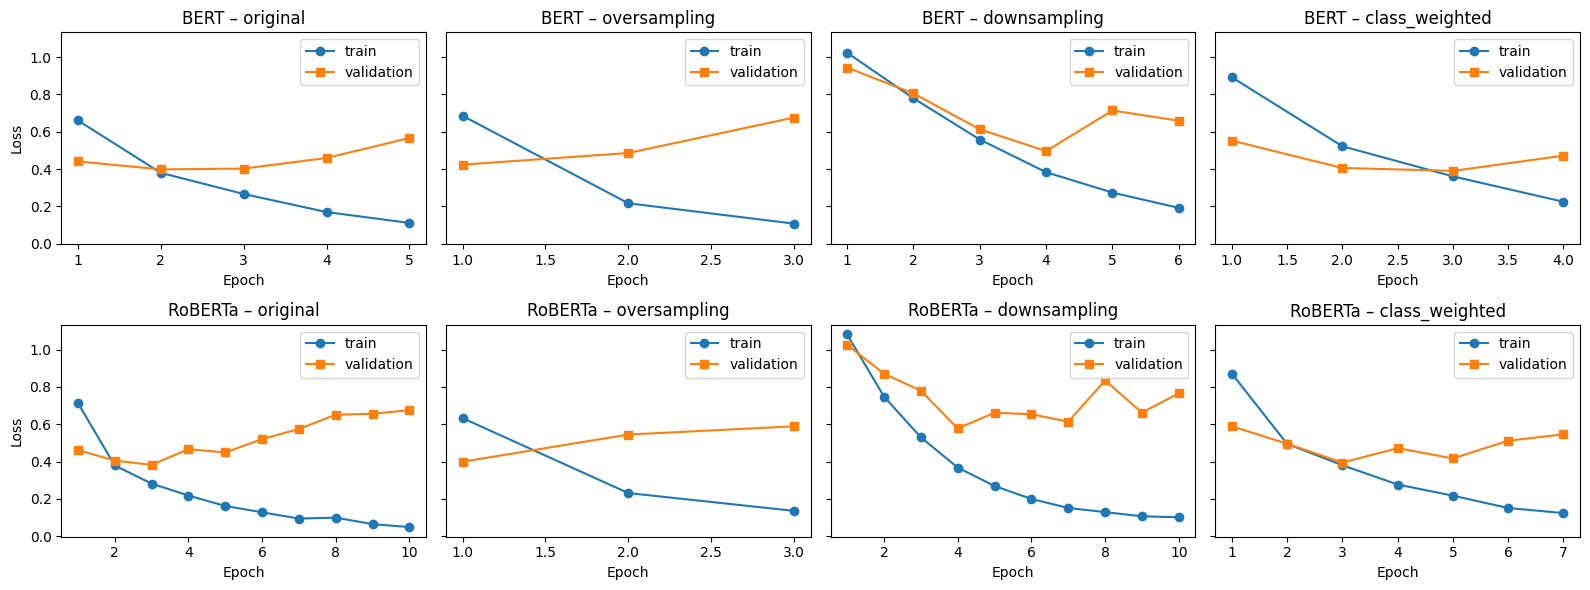

In [ ]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
for i, n in enumerate(['BERT', 'RoBERTa']):
    for j, sc in enumerate(SCENARIOS):
        ax = axs[i, j]; f = f'{OUT_DIR}/hist/{n}_{sc}_standard_42.json'
        if os.path.exists(f):
            h = pd.DataFrame(json.load(open(f)))
            ax.plot(h.epoch, h.train_loss, 'o-', label='train'); ax.plot(h.epoch, h.val_loss, 's-', label='validation')
        ax.set_title(f'{n} – {sc}'); ax.set_xlabel('Epoch'); ax.legend()
axs[0, 0].set_ylabel('Loss'); axs[1, 0].set_ylabel('Loss')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/loss_curves_seed42.png', dpi=200); plt.show()

## hasil



In [ ]:
import shutil
shutil.make_archive('/content/hasil_revisi', 'zip', OUT_DIR)from google.colab import files; files.download('/content/hasil_revisi.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>